# Домашняя работа №1

По условию пользователи должны распределяться в группы 50/50, независимо
от активности до эксперимента. Основная метрика — конверсия `converted`.
Защитная метрика — ошибки загрузки `error_flag`. Уровень значимости будет
равен 0,05. Все статистические проверки будут двусторонними.

## 1. Исходные данные

Использую подготовленный файл `experiment_data.csv`. Загружаю
сохранённые данные, без повторной генерации и изменения исходных строк.

In [ ]:
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Image

ALPHA = 0.05
groups = ['control', 'test']
colors = ['#3478bf', '#dc7855']
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

In [ ]:
metadata = {'source': 'Предоставленный файл experiment_data.csv', 'n_users': 9273, 'csv_sha256': 'be2329600fde1c6702765021c1e25b49417ba58f356462139a0697e1ac78ee6a'}
if not Path('experiment_data.csv').exists():
    raise FileNotFoundError('Положите исходный experiment_data.csv рядом с ноутбуком.')
print('Использую сохранённый файл experiment_data.csv.')
print('Число строк в исходном файле:', metadata['n_users'])

Использую сохранённый файл experiment_data.csv.
Число строк в исходном файле: 9273


## 2. Первичная проверка данных

Единицей анализа будет пользователь. Проверю, что каждому `user_id`
соответствует одна строка, нет пропусков, обе группы присутствуют, а значения
конверсии и ошибок равны 0 или 1. Затем посчитаю основные показатели по группам.

In [ ]:
df = pd.read_csv('experiment_data.csv', parse_dates=['date'])
expected_columns = {'user_id', 'variant', 'converted', 'error_flag', 'pre_activity', 'date'}
assert set(df.columns) == expected_columns, 'Неожиданный состав столбцов'
assert not df.empty and not df.isna().any().any(), 'Есть пропуски или данные пустые'
assert df.user_id.is_unique, 'Найдены повторные пользователи'
assert set(df.variant) == set(groups), 'Некорректные группы'
assert df[['converted', 'error_flag']].isin([0, 1]).all().all(), 'Метрики должны быть бинарными'
assert np.isfinite(df.pre_activity).all() and df.pre_activity.ge(0).all(), 'Некорректная активность'
assert df.date.between('2026-05-01', '2026-05-14').all(), 'Дата вне периода эксперимента'
assert len(df) == metadata['n_users']
assert hashlib.sha256(Path('experiment_data.csv').read_bytes()).hexdigest() == metadata['csv_sha256']

print('Размер таблицы:', df.shape)
print('Пропуски:', df.isna().sum().sum())
print('Повторные user_id:', df.user_id.duplicated().sum())
display(df.head())

summary = df.groupby('variant').agg(
    users=('user_id', 'size'),
    conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean'),
    errors=('error_flag', 'sum'),
    error_rate=('error_flag', 'mean'),
    activity_mean=('pre_activity', 'mean'),
    activity_median=('pre_activity', 'median'),
).reindex(groups)
summary['share'] = summary.users / len(df)
display(summary.round(4))

Размер таблицы: (9273, 6)
Пропуски: 0
Повторные user_id: 0


,user_id,variant,converted,error_flag,pre_activity,date
0,0,test,0,0.0,0,2026-05-13
1,1,control,0,0.0,33,2026-05-06
2,2,control,0,0.0,21,2026-05-14
3,3,control,0,0.0,3,2026-05-04
4,4,test,0,0.0,7,2026-05-01


,users,conversions,conversion_rate,errors,error_rate,activity_mean,activity_median,share
variant,,,,,,,,
control,5294,272,0.0514,62.0,0.0117,9.1560,6.0,0.5709
test,3979,232,0.0583,79.0,0.0199,10.2003,7.0,0.4291


## 3. Проверка соотношения групп — SRM

Нулевая гипотеза: распределение участников соответствует плану 50/50.
Будем использовать критерий χ² Пирсона, сравним наблюдаемые размеры с ожидаемыми N/2.
Если p-value меньше 0,05, сообщим об этом

In [ ]:
warnings = []
observed = summary.users.to_numpy()
expected = np.array([len(df) / 2, len(df) / 2])
srm = stats.chisquare(observed, f_exp=expected)
print('Наблюдаемые размеры:', observed)
print('Ожидаемые размеры:', expected)
print(f'χ² = {srm.statistic:.3f}; p-value = {srm.pvalue:.6g}')
if srm.pvalue < ALPHA:
    warnings.append('SRM обнаружен')
    print(warnings[-1])
else:
    print('Статистически значимый SRM не обнаружен.')

Наблюдаемые размеры: [5294 3979]
Ожидаемые размеры: [4636.5 4636.5]
χ² = 186.480; p-value = 1.86553e-42
SRM обнаружен


В контроле оказалось **5294 пользователей
(57.09%)**, в тесте — **3979
(42.91%)**. p-value = **1.87e-42**.
Соотношение статистически значимо отличается от 50/50. План распределения нарушен.

## 4. Баланс активности до эксперимента

Активность измерена до воздействия, поэтому вариант эксперимента не должен
на неё влиять. Посмотрим на распределение и проверим равенство распределений
с помощью U-теста Манна—Уитни. Он подходит здесь из-за сильной правой
асимметрии. Средние и медианы покажем отдельно.
Для повторяющихся целочисленных значений используем асимптотическую поправку.

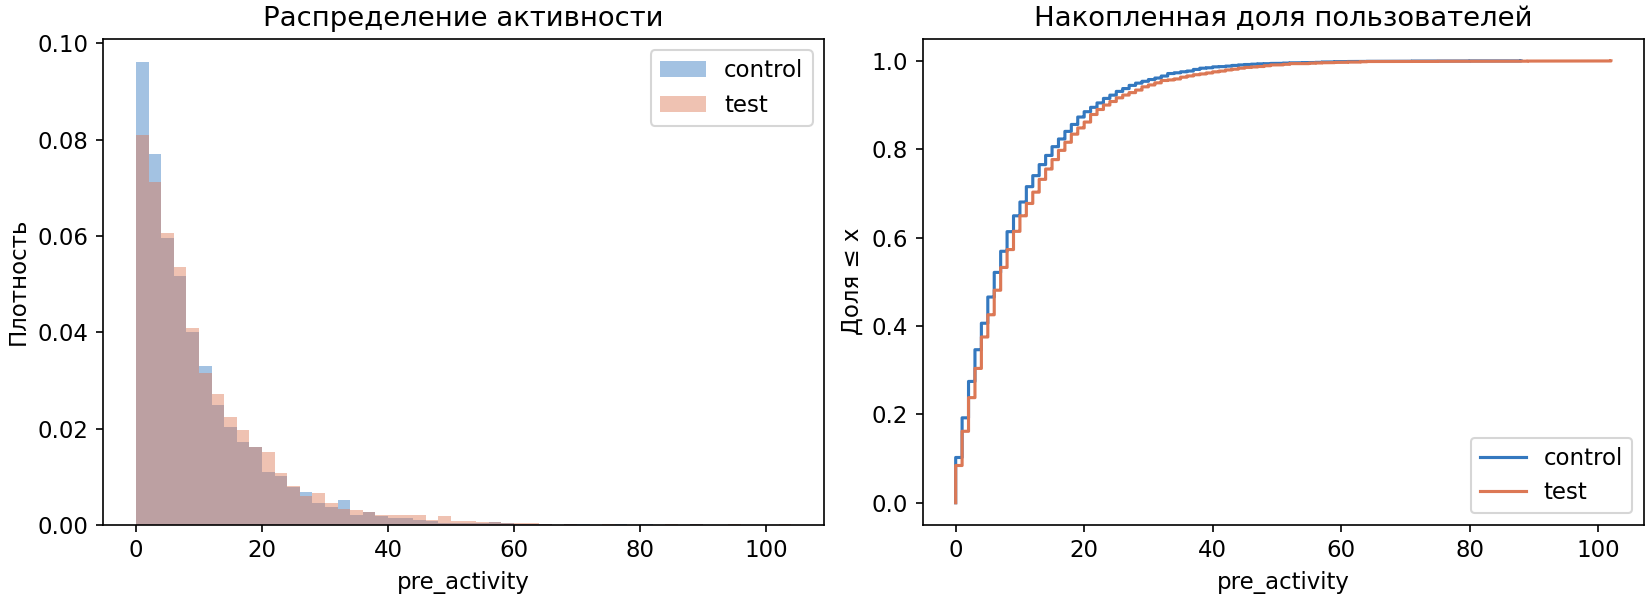

Средняя активность: control=9.156; test=10.200
Медианы: control=6.0; test=7.0
U = 11142921.0; p-value = 1.64467e-06; SMD = 0.102
Дисбаланс по pre_activity — возможен confounder


In [ ]:
control = df.loc[df.variant.eq('control')].copy()
test = df.loc[df.variant.eq('test')].copy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
bins = np.arange(0, df.pre_activity.max() + 3, 2)
for group, color in zip(groups, colors):
    values = df.loc[df.variant.eq(group), 'pre_activity']
    axes[0].hist(values, bins=bins, density=True, alpha=0.45, label=group, color=color)
    x = np.sort(values)
    axes[1].step(x, np.arange(1, len(x) + 1) / len(x), where='post', label=group, color=color)
axes[0].set(title='Распределение активности', xlabel='pre_activity', ylabel='Плотность')
axes[1].set(title='Накопленная доля пользователей', xlabel='pre_activity', ylabel='Доля ≤ x')
for ax in axes:
    ax.legend()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/activity.png', dpi=150)
plt.close(fig)
display(Image(filename='figures/activity.png'))

balance = stats.mannwhitneyu(test.pre_activity, control.pre_activity,
                           alternative='two-sided', method='asymptotic')
pooled_sd = np.sqrt((test.pre_activity.var() + control.pre_activity.var()) / 2)
smd = (test.pre_activity.mean() - control.pre_activity.mean()) / pooled_sd
print(f'Средняя активность: control={control.pre_activity.mean():.3f}; test={test.pre_activity.mean():.3f}')
print(f'Медианы: control={control.pre_activity.median():.1f}; test={test.pre_activity.median():.1f}')
print(f'U = {balance.statistic:.1f}; p-value = {balance.pvalue:.6g}; SMD = {smd:.3f}')
if balance.pvalue < ALPHA:
    warnings.append('Дисбаланс по pre_activity — возможен confounder')
    print(warnings[-1])
else:
    print('Значимое различие распределений активности не обнаружено.')

p-value U-теста равен **1.645e-06**.
Различие значимо, группы отличаются ещё до воздействия.
SMD = **0.102** - это разница средних, делённая на корень из
среднего двух выборочных дисперсий.

В генераторе вероятность назначения в тест равна
`0.4 + 0.3 * pre_activity / pre_activity.max()`. Активность также влияет на
вероятность конверсии. Получается, что она связана и с группой, и с исходом,
поэтому может смешиваться с эффектом варианта. Даже незначимый U-тест
не исправил бы известную из кода зависимость назначения от активности.

## 5. Защитная метрика: ошибки загрузки

Сравним доли ошибок в группах точным тестом Фишера. Он позволяет работать
с редкими событиями.
Нулевая гипотеза - частоты ошибок одинаковы.
Кроме p-value покажем абсолютную разницу в процентных пунктах,
это поможет понять размер ухудшения, а не только его значимость.

,errors,users,error_rate
variant,,,
control,62.0,5294,0.011711
test,79.0,3979,0.019854


Разница test − control: 0.814 п.п.; p-value = 0.00192876
Дисбаланс guardrail — частоты ошибок различаются


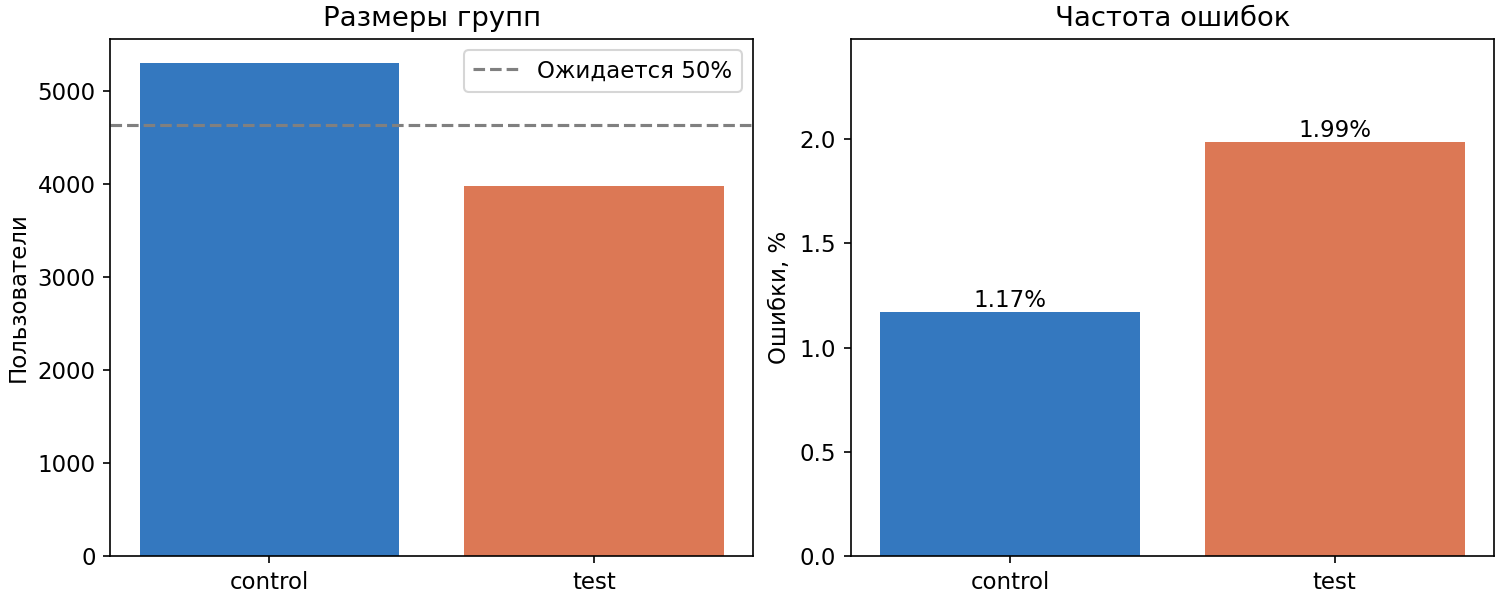

In [ ]:
def compare_binary(data, metric):
    grouped = data.groupby('variant')[metric].agg(['sum', 'count', 'mean']).reindex(groups)
    table = np.column_stack([grouped['sum'], grouped['count'] - grouped['sum']]).astype(int)
    p = stats.fisher_exact(table, alternative='two-sided').pvalue
    difference_pp = 100 * (grouped.loc['test', 'mean'] - grouped.loc['control', 'mean'])
    return grouped, float(p), float(difference_pp)

errors, error_p, error_diff = compare_binary(df, 'error_flag')
display(errors.rename(columns={'sum': 'errors', 'count': 'users', 'mean': 'error_rate'}))
print(f'Разница test − control: {error_diff:.3f} п.п.; p-value = {error_p:.6g}')
if error_p < ALPHA:
    warnings.append('Дисбаланс guardrail — частоты ошибок различаются')
    print(warnings[-1])
else:
    print('Значимое различие частот ошибок не обнаружено.')

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].bar(groups, summary.users, color=colors)
axes[0].axhline(len(df) / 2, color='gray', linestyle='--', label='Ожидается 50%')
axes[0].set(title='Размеры групп', ylabel='Пользователи')
axes[0].legend()
axes[1].bar(groups, 100 * errors['mean'], color=colors)
for i, rate in enumerate(errors['mean']):
    axes[1].text(i, 100 * rate, f'{100 * rate:.2f}%', ha='center', va='bottom')
axes[1].set(title='Частота ошибок', ylabel='Ошибки, %', ylim=(0, 100 * errors['mean'].max() * 1.25))
fig.savefig('figures/groups_errors.png', dpi=150)
plt.close(fig)
display(Image(filename='figures/groups_errors.png'))

Частота ошибок: **1.171%** в контроле и
**1.985%** в тесте. В тесте она выше на
**0.814 п.п.**, p-value = **0.001929**.
Различие статистически значимо.

В скрипте вероятности ошибок заданы как 1% и 2%, поэтому ожидаемое ухудшение
заложено в генерацию. Выборочные частоты не обязаны совпадать с этими числами.
Условие «истинного эффекта нет» относится к конверсии, для ошибок эффект задан.

## 6. Решение о валидности эксперимента

По условию достаточно хотя бы одного предупреждения, чтобы остановить тест.
Подтверждающий анализ конверсии проводим только при отсутствии предупреждений.

In [ ]:
if warnings:
    print('Найдены проблемы:')
    for message in warnings:
        print('•', message)
    decision = 'Остановить тест, исправить ошибки, перезапустить'
    print('\nВывод:', decision)
else:
    conversion, conversion_p, conversion_diff = compare_binary(df, 'converted')
    display(conversion)
    print(f'Разница конверсий: {conversion_diff:.3f} п.п.; p-value = {conversion_p:.6g}')
    decision = 'Конверсия различается значимо' if conversion_p < ALPHA else 'Значимое различие конверсии не обнаружено'
    print('Вывод:', decision)

Найдены проблемы:
• SRM обнаружен
• Дисбаланс guardrail — частоты ошибок различаются
• Дисбаланс по pre_activity — возможен confounder
• Дисбаланс guardrail — частоты ошибок различаются

Вывод: Остановить тест, исправить ошибки, перезапустить


Статистические проверки подтверждают только то, что видно на данной выборке.
Для нескольких проверок использован порог 0,05 по условию, без поправки на множественность,
поэтому общая вероятность ложного предупреждения может быть выше 5%.

## 7. Дополнительная часть

Попробуем исправить дисбаланс наблюдаемой ковариаты точным сопоставлением.
Для каждого значения `pre_activity` оставим одинаковое число пользователей
из теста и контроля. Строки выберем случайно с фиксированным seed, не используя
конверсию или ошибки.

Результат будет относиться к сопоставимой подвыборке, а не ко
всем участникам.

In [ ]:
rng = np.random.default_rng(42)
selected = []
for activity, block in df.groupby('pre_activity'):
    control_index = block.index[block.variant.eq('control')].to_numpy()
    test_index = block.index[block.variant.eq('test')].to_numpy()
    size = min(len(control_index), len(test_index))
    selected.extend(rng.choice(control_index, size=size, replace=False))
    selected.extend(rng.choice(test_index, size=size, replace=False))
matched = df.loc[sorted(selected)].copy()
assert not matched.empty
matched_counts = pd.crosstab(matched.pre_activity, matched.variant).reindex(columns=groups)
assert matched_counts.control.eq(matched_counts.test).all()

rows = []
for name, data in [('До сопоставления', df), ('После сопоставления', matched)]:
    activity_groups = [data.loc[data.variant.eq(g), 'pre_activity'] for g in groups]
    activity_p = stats.mannwhitneyu(*activity_groups, alternative='two-sided', method='asymptotic').pvalue
    means = data.groupby('variant').pre_activity.mean()
    _, conv_p, conv_diff = compare_binary(data, 'converted')
    _, err_p, err_diff = compare_binary(data, 'error_flag')
    rows.append({'sample': name, 'users': len(data),
                 'activity_difference': means['test'] - means['control'],
                 'activity_p': activity_p, 'conversion_diff_pp': conv_diff,
                 'conversion_p': conv_p, 'error_diff_pp': err_diff, 'error_p': err_p})
comparison = pd.DataFrame(rows).set_index('sample')
display(comparison.round(6))
print(f'Сохранено {len(matched)} из {len(df)} пользователей ({len(matched) / len(df):.1%}).')
summary.to_csv('group_summary.csv')
comparison.to_csv('matching_comparison.csv')

,users,activity_difference,activity_p,conversion_diff_pp,conversion_p,error_diff_pp,error_p
sample,,,,,,,
До сопоставления,9273,1.044276,0.000002,0.692719,0.151471,0.814286,0.001929
После сопоставления,7810,0.000000,1.000000,0.588988,0.277694,0.947503,0.000811


Сохранено 7810 из 9273 пользователей (84.2%).


После сопоставления осталось **7810 пользователей**.
Распределения активности совпадают точно, поэтому p-value U-теста равен 1
по построению. Это результат отбора строк, а не доказательство исправления
рандомизации.

Для иллюстрации сравним конверсию до и после: разница изменилась с
**0.693** до **0.589 п.п.**,
а p-value — с **0.1515** до **0.2777**.
Эти расчёты тестовые, исходный тест не прошёл проверку валидности,
поэтому интерпритировать их как успех нельзя. Коррекция
не обязана приблизить выборочную разность к нулю, меняются состав и размер данных.

Разница ошибок после сопоставления — **0.948 п.п.**,
p-value = **0.0008**. Даже если значимость пропадает после сокращения
выборки, это не доказывает, что проблему ошибок удалось устранить.
Решение о перезапуске исходного эксперимента остаётся прежним.

## 8. Итоговый вывод

В полученной выборке сработало **3 предупреждений**.
Мой вывод: **Остановить тест, исправить ошибки, перезапустить**.

Из скрипта видно, что назначение зависит от активности, хотя в корректном
эксперименте должно быть независимым. Кроме того, для теста задана повышенная
вероятность ошибок. Поэтому наблюдаемую разницу конверсии нельзя трактовать
как надёжный результат корректного A/B-теста.

Для исправления я бы предложил:

1. Настроить устойчивое назначение пользователей с вероятностью 0,5 в каждую
   группу, независимо от активности. Убрать повторное присваивание `variant`.
2. Проверить, одинаково ли собираются события и нет ли потерь пользователей
   в логах. Исправить причину ошибок загрузки в тесте или различие их измерения.
3. Провести A/A-проверку назначения и сбора данных, затем запустить новый тест.
   Заранее задать размер выборки, минимальный интересующий эффект, длительность
   и допустимое ухудшение защитной метрики.

Удалять пользователей с ошибками я бы не стал: ошибка возникает после
назначения, поэтому такой отбор может дополнительно сместить сравнение.
Сопоставление по активности полезно для диагностики, но не заменяет перезапуск.